### Coco Renfroe
## 9/18/2026
## Liked Post Assignment

**Who or what is the source of your personal Instagram data?**
Meta owns the data and creates the JSON file when you request the download. The source is my instagram profile through Meta

**Why was this data created and what purposes can the data serve?**
It was created to give the user/requester statistics regarding their account. It can answer a hypothesis posed and can support or refute the hypothesis based on what the data shows

**In what ways may this data be reliable?**
It will give you a concrete number in regard to certain stats about your instagram profile. The numbers don't lie, so if you're wondering how many posts you liked from someone, for instance, it will give you that information in an unbiased sense

**In what ways may this data be unreliable?**
Even though numbers are concrete, depending on how they are presented by a user, they can be manipulated. The examples provided by Dr. Baumgartner in class about climate change which were manipulated by the Republican party in the 2000s are a great example. If someone is not well versed in how data can be manipulated, they may take numbers at face value and assume they can't be manipulated

### Source of my data
This data comes from my download request from Instagram. I exported my data as JSON files and used my liked posts and my saved posts to test my hypothesis

In [1]:
import json
import pandas as pd

with open ('liked_posts.json','r') as f:
    data = json.load(f)

data[0]

{'timestamp': 1788137909,
 'media': [],
 'label_values': [{'label': 'URL',
   'value': 'https://www.instagram.com/reel/DVxEdJbN8ei/',
   'href': 'https://www.instagram.com/reel/DVxEdJbN8ei/'},
  {'label': 'Caption',
   'value': '#ai #artificalintelligence #grok #standup #crowdwork'},
  {'label': 'Title', 'value': ''},
  {'dict': [{'dict': [{'label': 'Name', 'value': 'grok'}], 'title': ''},
    {'dict': [{'label': 'Name', 'value': 'ai'}], 'title': ''},
    {'dict': [{'label': 'Name', 'value': 'standup'}], 'title': ''},
    {'dict': [{'label': 'Name', 'value': 'artificalintelligence'}],
     'title': ''},
    {'dict': [{'label': 'Name', 'value': 'crowdwork'}], 'title': ''}],
   'title': 'Hashtags'},
  {'dict': [{'dict': [{'label': 'URL',
       'value': 'https://chirp.me/theglennisshow'},
      {'label': 'Name', 'value': 'Glennis LaRoe'},
      {'label': 'Username', 'value': 'theglennisshow'}],
     'title': ''}],
   'title': 'Owner'},
  {'dict': [], 'title': 'Brand partner'}],
 'fbid': 

In [2]:
row ={}
row['timestamp']= data[0]['timestamp']

row

{'timestamp': 1788137909}

In [3]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']

row

{'timestamp': 1788137909,
 'URL': 'https://www.instagram.com/reel/DVxEdJbN8ei/',
 'Caption': '#ai #artificalintelligence #grok #standup #crowdwork',
 'Title': ''}

In [4]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']
    elif item.get('title') == 'Owner ':
        owner_fields = item['dict'][0]['dict']
        for owner_item in owner_fields:
            row['owner ' + owner_item['label']] = owner_item['value']

row

{'timestamp': 1788137909,
 'URL': 'https://www.instagram.com/reel/DVxEdJbN8ei/',
 'Caption': '#ai #artificalintelligence #grok #standup #crowdwork',
 'Title': ''}

In [5]:
tidy_rows = []

for entry in data:
    row = {}
    row['timestamp'] = entry['timestamp']

    for item in entry['label_values']:
        if 'label' in item:
            row[item['label']] = item['value']
        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']
            for owner_item in owner_fields:
                row['owner ' + owner_item['label']] = owner_item['value']
    tidy_rows.append(row)

tidy_rows[:2]

[{'timestamp': 1788137909,
  'URL': 'https://www.instagram.com/reel/DVxEdJbN8ei/',
  'Caption': '#ai #artificalintelligence #grok #standup #crowdwork',
  'Title': '',
  'owner URL': 'https://chirp.me/theglennisshow',
  'owner Name': 'Glennis LaRoe',
  'owner Username': 'theglennisshow'},
 {'timestamp': 1788137791,
  'URL': 'https://www.instagram.com/reel/DcRBL03CXce/',
  'Caption': 'Earlier this year I made a video on Black womenâ\x80\x99s inventions and so I had to make a part 2. So many of these inventions were made for public safety and public good with no profit incentive.\n\n(Note that the last two were co-inventors of their inventions)',
  'Title': '',
  'owner URL': 'http://linktr.ee/nikitadumptruck',
  'owner Name': 'Nikita Redkar',
  'owner Username': 'nikitadumptruck'}]

In [6]:
likes_df = pd.DataFrame(tidy_rows)
likes_df.head(10)

,timestamp,URL,Caption,Title,owner URL,owner Name,owner Username
0,1788137909,https://www.instagram.com/reel/DVxEdJbN8ei/,#ai #artificalintelligence #grok #standup #cro...,,https://chirp.me/theglennisshow,Glennis LaRoe,theglennisshow
1,1788137791,https://www.instagram.com/reel/DcRBL03CXce/,Earlier this year I made a video on Black wome...,,http://linktr.ee/nikitadumptruck,Nikita Redkar,nikitadumptruck
2,1788137740,https://www.instagram.com/reel/DcCnBonI2vn/,"Someone needs to say it, we all think it!\n\nB...",,https://www.comfrt.com/LAUREN34591,Lauren ð§¿â¨ Branding Opinions & Advice,laurensh.rt
3,1788137707,https://www.instagram.com/reel/DbUIiTAy6Yy/,"Turns out, not that typical. ð«©\n \n\nSteph ...",,https://linktr.ee/rootandgrowEMDR,Stephanie Brashear | EMDR Therapist & Consultant,steph.goes.with.that
4,1788137696,https://www.instagram.com/reel/DbWxiX1gICj/,it actually quite simple over here.\n\n#americ...,,https://www.godsfavoritecomedian.com/,Spencer Bland,spencerspicy
5,1788137638,https://www.instagram.com/reel/Da0hYuwxjGr/,If you live in Pittsburgh you may already know...,,https://linktr.ee/biancablack,Bianca Black Pittsburgh Photographer and Conte...,biancablack_
6,1788137628,https://www.instagram.com/reel/DcrCeUapj5u/,Give it up for the mayor of our hearts @nycmay...,,https://linktr.ee/Glossestudio.id,GlossÃ© Studio,glosse_studio.id
7,1788137528,https://www.instagram.com/reel/Db6SQ7aRdx_/,NaN,NaN,,Daniela Sandoval,da_nielas
8,1788134248,https://www.instagram.com/p/DcBiDX1DCNV/,The wisest man in Athens built his entire phil...,,https://the-philosophers-shirt.com,The Philosopher's Shirt,the_philosophers_shirt
9,1788134146,https://www.instagram.com/reel/Dap09-riFK_/,Robert Irwin shares his thoughts on AI and its...,,,PARADE Magazine,parademag


In [7]:
likes_df['date_and_time']= pd.to_datetime(likes_df['timestamp'], unit= 's')
likes_df[['timestamp', 'date_and_time']].head()

,timestamp,date_and_time
0,1788137909,2026-08-31 00:58:29
1,1788137791,2026-08-31 00:56:31
2,1788137740,2026-08-31 00:55:40
3,1788137707,2026-08-31 00:55:07
4,1788137696,2026-08-31 00:54:56


In [8]:
likes_df.head(10)

,timestamp,URL,Caption,Title,owner URL,owner Name,owner Username,date_and_time
0,1788137909,https://www.instagram.com/reel/DVxEdJbN8ei/,#ai #artificalintelligence #grok #standup #cro...,,https://chirp.me/theglennisshow,Glennis LaRoe,theglennisshow,2026-08-31 00:58:29
1,1788137791,https://www.instagram.com/reel/DcRBL03CXce/,Earlier this year I made a video on Black wome...,,http://linktr.ee/nikitadumptruck,Nikita Redkar,nikitadumptruck,2026-08-31 00:56:31
2,1788137740,https://www.instagram.com/reel/DcCnBonI2vn/,"Someone needs to say it, we all think it!\n\nB...",,https://www.comfrt.com/LAUREN34591,Lauren ð§¿â¨ Branding Opinions & Advice,laurensh.rt,2026-08-31 00:55:40
3,1788137707,https://www.instagram.com/reel/DbUIiTAy6Yy/,"Turns out, not that typical. ð«©\n \n\nSteph ...",,https://linktr.ee/rootandgrowEMDR,Stephanie Brashear | EMDR Therapist & Consultant,steph.goes.with.that,2026-08-31 00:55:07
4,1788137696,https://www.instagram.com/reel/DbWxiX1gICj/,it actually quite simple over here.\n\n#americ...,,https://www.godsfavoritecomedian.com/,Spencer Bland,spencerspicy,2026-08-31 00:54:56
5,1788137638,https://www.instagram.com/reel/Da0hYuwxjGr/,If you live in Pittsburgh you may already know...,,https://linktr.ee/biancablack,Bianca Black Pittsburgh Photographer and Conte...,biancablack_,2026-08-31 00:53:58
6,1788137628,https://www.instagram.com/reel/DcrCeUapj5u/,Give it up for the mayor of our hearts @nycmay...,,https://linktr.ee/Glossestudio.id,GlossÃ© Studio,glosse_studio.id,2026-08-31 00:53:48
7,1788137528,https://www.instagram.com/reel/Db6SQ7aRdx_/,NaN,NaN,,Daniela Sandoval,da_nielas,2026-08-31 00:52:08
8,1788134248,https://www.instagram.com/p/DcBiDX1DCNV/,The wisest man in Athens built his entire phil...,,https://the-philosophers-shirt.com,The Philosopher's Shirt,the_philosophers_shirt,2026-08-30 23:57:28
9,1788134146,https://www.instagram.com/reel/Dap09-riFK_/,Robert Irwin shares his thoughts on AI and its...,,,PARADE Magazine,parademag,2026-08-30 23:55:46


# My Hypothesis


My hypothesis is that most of the posts/reels I save the most on instagram are pets/animal related as those are the videos I enjoy showing my husband. I believe that animal related posts will be either half (50%) or nearly half of my saved posts on instagram.

I will test this hypothesis by looking at my saved posts and determining if they are related to animal/pet content through the captions or hashtags

In [9]:
import pandas as pd
df= pd.DataFrame
import json
with open('saved_posts.json', 'r') as saved:
    data= json.load(saved)
    

I believe this file contains the metadata for all of my saved posts on instagram.

In [10]:
data[0]


{'timestamp': 1788137545,
 'media': [],
 'label_values': [{'label': 'URL',
   'value': 'https://www.instagram.com/reel/Db6SQ7aRdx_/',
   'href': 'https://www.instagram.com/reel/Db6SQ7aRdx_/'},
  {'dict': [], 'title': 'Hashtags'},
  {'dict': [{'dict': [{'label': 'URL', 'value': ''},
      {'label': 'Name', 'value': 'Daniela Sandoval'},
      {'label': 'Username', 'value': 'da_nielas'}],
     'title': ''}],
   'title': 'Owner'},
  {'dict': [], 'title': 'Brand partner'}],
 'fbid': '18099835475248648'}

Using the code we did in class, the next cell will tidy the nested data

In [11]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']

In [12]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']
    elif item.get('title') == 'Owner ':
        owner_fields = item['dict'][0]['dict']
        for owner_item in owner_fields:
            row['owner ' + owner_item['label']] = owner_item['value']

In [13]:
tidy_rows = []


for entry in data:
    row = {}
    row['timestamp'] = entry['timestamp']

    

    for item in entry['label_values']:
        if 'label' in item:
            row[item['label']] = item['value']
        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']
            for owner_item in owner_fields:
                row['owner ' + owner_item['label']] = owner_item['value']
    tidy_rows.append(row)

tidy_rows[:2]

[{'timestamp': 1788137545,
  'URL': 'https://www.instagram.com/reel/Db6SQ7aRdx_/',
  'owner URL': '',
  'owner Name': 'Daniela Sandoval',
  'owner Username': 'da_nielas'},
 {'timestamp': 1788132857,
  'URL': 'https://www.instagram.com/reel/DaZXXCdC0Fh/',
  'Caption': 'I feel like there was a pretty clear winner but Iâ\x80\x99m open to arguments ð\x9f\x98\x82\n\n#messy #kittens #gremlins',
  'Title': '',
  'owner URL': 'https://www.greekgardenmainecoons.com',
  'owner Name': 'Greek Garden Maine Coons',
  'owner Username': 'mainegreekgarden'}]

In [14]:
saved_df = pd.DataFrame(tidy_rows)

In [15]:
saved_df.head(10)

,timestamp,URL,owner URL,owner Name,owner Username,Caption,Title
0,1788137545,https://www.instagram.com/reel/Db6SQ7aRdx_/,,Daniela Sandoval,da_nielas,NaN,NaN
1,1788132857,https://www.instagram.com/reel/DaZXXCdC0Fh/,https://www.greekgardenmainecoons.com,Greek Garden Maine Coons,mainegreekgarden,I feel like there was a pretty clear winner bu...,
2,1788128873,https://www.instagram.com/p/DcrbyLxE-8q/,https://vm.tiktok.com/vEyEHr/,Zach Mander,zachmander,I changed the text on Richard Scarry illustrat...,
3,1788063381,https://www.instagram.com/reel/Db6E5YRRLZl/,http://www.troublesomegirlstudios.com,Torrey Griffith,troublesomegirlstudios,Last year I wore a Luigi Mangione shirt to Tha...,
4,1788063339,https://www.instagram.com/reel/DcOKcyMhnm3/,https://lovefromlottie.com,Handmade Retro Toddler Clothing Australia,lovefromlottieau,"My bad back says granny, my hobbies say granny...",
5,1788061889,https://www.instagram.com/reel/DZWC5huxKb4/,http://linktr.ee/vetmedredhead,"Jade, LVT ð©ºð¾",vetmed.redhead,The amount of visceral cringe I experienced ma...,
6,1788060779,https://www.instagram.com/reel/Dbs_g54Aupg/,https://linktr.ee/amir_thevet,Amir Anwary,amir_the_vet,Some female tortoise shells can be a hell of a...,
7,1788060257,https://www.instagram.com/reel/Db_BlBMM68O/,https://linktr.ee/amir_thevet,Amir Anwary,amir_the_vet,The females that have just turned 2 years old ...,
8,1788060162,https://www.instagram.com/reel/DcjyYXJgFuV/,http://tinytownvet.com,Tiny Town Animal Clinic,tinytownanimalclinic,Have no fearâ¦ Crouton is here! ð±ð¾ð©ºð...,
9,1788060006,https://www.instagram.com/reel/DckMtgbNOFc/,,Lobotomized Barbie,lobotomized_barbie,I have one person to thank for introducing me ...,


In [16]:
saved_df.head(10)

,timestamp,URL,owner URL,owner Name,owner Username,Caption,Title
0,1788137545,https://www.instagram.com/reel/Db6SQ7aRdx_/,,Daniela Sandoval,da_nielas,NaN,NaN
1,1788132857,https://www.instagram.com/reel/DaZXXCdC0Fh/,https://www.greekgardenmainecoons.com,Greek Garden Maine Coons,mainegreekgarden,I feel like there was a pretty clear winner bu...,
2,1788128873,https://www.instagram.com/p/DcrbyLxE-8q/,https://vm.tiktok.com/vEyEHr/,Zach Mander,zachmander,I changed the text on Richard Scarry illustrat...,
3,1788063381,https://www.instagram.com/reel/Db6E5YRRLZl/,http://www.troublesomegirlstudios.com,Torrey Griffith,troublesomegirlstudios,Last year I wore a Luigi Mangione shirt to Tha...,
4,1788063339,https://www.instagram.com/reel/DcOKcyMhnm3/,https://lovefromlottie.com,Handmade Retro Toddler Clothing Australia,lovefromlottieau,"My bad back says granny, my hobbies say granny...",
5,1788061889,https://www.instagram.com/reel/DZWC5huxKb4/,http://linktr.ee/vetmedredhead,"Jade, LVT ð©ºð¾",vetmed.redhead,The amount of visceral cringe I experienced ma...,
6,1788060779,https://www.instagram.com/reel/Dbs_g54Aupg/,https://linktr.ee/amir_thevet,Amir Anwary,amir_the_vet,Some female tortoise shells can be a hell of a...,
7,1788060257,https://www.instagram.com/reel/Db_BlBMM68O/,https://linktr.ee/amir_thevet,Amir Anwary,amir_the_vet,The females that have just turned 2 years old ...,
8,1788060162,https://www.instagram.com/reel/DcjyYXJgFuV/,http://tinytownvet.com,Tiny Town Animal Clinic,tinytownanimalclinic,Have no fearâ¦ Crouton is here! ð±ð¾ð©ºð...,
9,1788060006,https://www.instagram.com/reel/DckMtgbNOFc/,,Lobotomized Barbie,lobotomized_barbie,I have one person to thank for introducing me ...,


The next cell contains code that I used Claude to format to run all queries at the same time. I used the code from our "coffee ratings" first and altered it a bit to search these terms all at once


In [17]:
animal_words = ['cat','cats','dog','dogs','pet', 'puppy', 'kitten', 'animal', 'otter', 'goose', 'vet']
pattern = '|'.join(animal_words)

animal_posts = saved_df[saved_df['Caption'].str.contains(pattern, case=False, na=False)]
animal_posts.shape[0]  

17

In [18]:
saved_df.shape[0]

37

This query shows that out of my 37 saved posts, 17 were pet related 

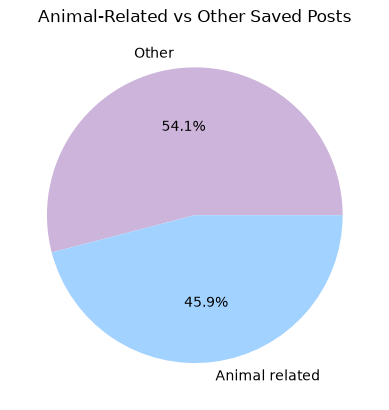

In [21]:

import matplotlib.pyplot as plt

animal_words = ['cat','cats','dog','dogs','pet', 'puppy', 'kitten', 'animal', 'otter', 'goose', 'vet']
pattern = '|'.join(animal_words)

is_animal = saved_df['Caption'].str.contains(pattern, case=False, na=False)

category_counts = is_animal.value_counts()
category_counts.index = ['Other', 'Animal related']  

category_counts.plot(kind='pie', autopct='%1.1f%%', colors=['#cdb4db', '#a2d2ff'])
plt.ylabel('')
plt.title('Animal-Related vs Other Saved Posts')
plt.show()

## Is this data tidy? 
I believe this data does pass as tidy data, as there are no nested elements within my table, and the data is labelled correctly. 
I did not translate the timestamp from Unix as it is not related to my hypothesis and was not required to test the hypothesis. 


## Conclusion

The conclusion that I came to understand from my saved post ratio is that I was on the right track, and ~45% of my saved posts are pet related according to the words I searched for. This may not seem like much as it's not over 50%, but I testted animal-related posts vs *all other* saved posts (aggregate).

There is a bit of room for inaccuracy as it's impossible to pass through every pet related word that may show up that isn't the typical "cat" or "dog" term, but this gives a good idea of what the majority of my saved posts on instagram would be if you were to look at my account. 

## Possible future data-wrangling
In the future, I may aggregate data from both instagram and youtube and test my hypothesis again, as I tend to spend more time on youtube and also watch a lot of long-form *and* short-form animal related videos which I save to show my spouse later.